In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import os


## Data manipulation and processing

In [3]:
df = pd.read_excel("/content/Sample_OD_PC TW.xlsx")
df.head()


,PC_OD Paid Amount,TW_OD Paid Amount,PC_Count,TW_Count
0,23840,1495,1,0
1,590,2812,0,0
2,10771,8760,0,0
3,23570,1400,0,0
4,76768,10295,1,0


In [4]:

# Print the actual column names from the DataFrame
print(df.columns)

# Strip leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Replace spaces with underscores in column names to match your code
df.columns = df.columns.str.replace(' ', '_')

# Now access the columns using the corrected names
summary = df[['PC_OD_Paid_Amount', 'TW_OD_Paid_Amount', 'PC_Count', 'TW_Count']].describe()
print(summary)


Index(['PC_OD Paid Amount ', 'TW_OD Paid Amount', 'PC_Count', 'TW_Count'], dtype='object')
       PC_OD_Paid_Amount  TW_OD_Paid_Amount     PC_Count     TW_Count
count       5.000000e+03       5.000000e+03  5000.000000  5000.000000
mean        1.623905e+04       7.181957e+03     0.087000     0.009600
std         4.058534e+04       2.254917e+04     0.281863     0.097518
min         2.500000e+02       1.200000e+02     0.000000     0.000000
25%         3.328000e+03       2.724500e+03     0.000000     0.000000
50%         7.915500e+03       4.465500e+03     0.000000     0.000000
75%         1.664825e+04       7.835000e+03     0.000000     0.000000
max         1.212100e+06       1.500000e+06     1.000000     1.000000


In [5]:

df.columns = df.columns.str.strip()

df['PC'] = df['PC_OD_Paid_Amount'] * df['PC_Count']
df['TW'] = df['TW_OD_Paid_Amount'] * df['TW_Count']
df.describe()

,PC_OD_Paid_Amount,TW_OD_Paid_Amount,PC_Count,TW_Count,PC,TW
count,5.000000e+03,5.000000e+03,5000.000000,5000.000000,5000.000000,5000.000000
mean,1.623905e+04,7.181957e+03,0.087000,0.009600,1232.989000,52.157400
std,4.058534e+04,2.254917e+04,0.281863,0.097518,7306.340093,736.092755
min,2.500000e+02,1.200000e+02,0.000000,0.000000,0.000000,0.000000
25%,3.328000e+03,2.724500e+03,0.000000,0.000000,0.000000,0.000000
50%,7.915500e+03,4.465500e+03,0.000000,0.000000,0.000000,0.000000
75%,1.664825e+04,7.835000e+03,0.000000,0.000000,0.000000,0.000000
max,1.212100e+06,1.500000e+06,1.000000,1.000000,217990.000000,25005.000000


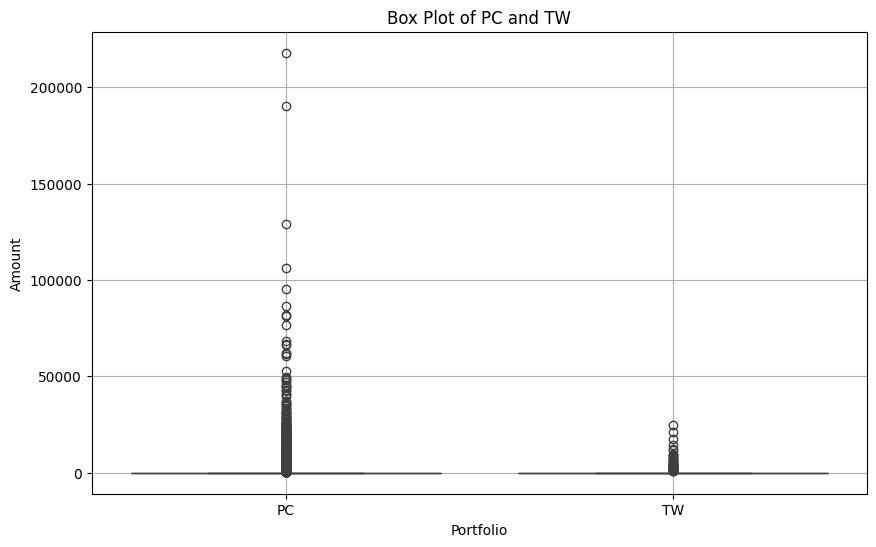

In [6]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[['PC', 'TW']], orient='v')
plt.title('Box Plot of PC and TW')
plt.xlabel('Portfolio')
plt.ylabel('Amount')
plt.xticks(ticks=[0, 1], labels=['PC', 'TW'])
plt.grid(True)
plt.show()

In [7]:
filtered_df = df[(df['PC'] != 0)]
filtered_df2 = df[(df['TW'] != 0)]
summary = filtered_df['PC'].describe()
summary2 = filtered_df2['TW'].describe()
print(summary)
print('--'*20)
print(summary2)

count       435.000000
mean      14172.287356
std       20762.513992
min         250.000000
25%        3499.000000
50%        8205.000000
75%       17390.500000
max      217990.000000
Name: PC, dtype: float64
----------------------------------------
count       48.00000
mean      5433.06250
std       5270.04943
min        794.00000
25%       2290.25000
50%       3158.00000
75%       6841.75000
max      25005.00000
Name: TW, dtype: float64


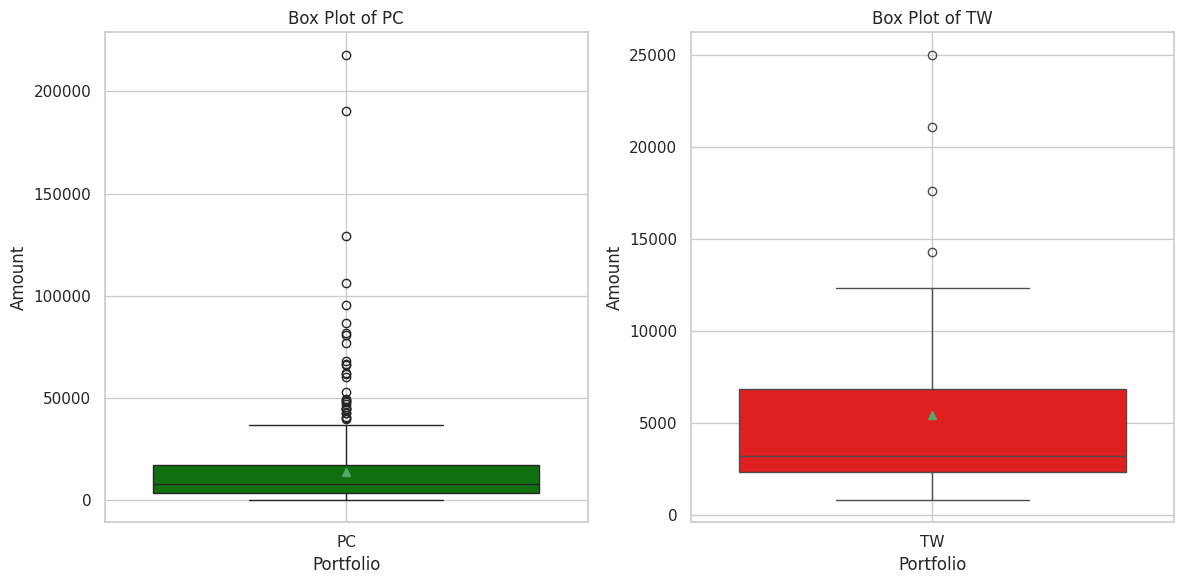

In [83]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'filtered_df' and 'filtered_df2' are your DataFrames containing 'PC' and 'TW' columns

# Calculate Interquartile Range (IQR) for PC
pc_q1 = np.percentile(filtered_df['PC'], 25)  # 25th percentile (first quartile)
pc_q3 = np.percentile(filtered_df['PC'], 75)  # 75th percentile (third quartile)
pc_iqr = pc_q3 - pc_q1  # IQR

# Calculate upper bound for potential outliers in PC
pc_upper_bound = pc_q3 + 1.5 * pc_iqr

pc_outliers = filtered_df.loc[filtered_df['PC'] > pc_upper_bound, 'PC']
num_pc_outliers = len(pc_outliers)
total_pc = len(filtered_df['PC'])
pc_outlier_percentage = (num_pc_outliers / total_pc) * 100

# Repeat the process for TW
tw_q1 = np.percentile(filtered_df2['TW'], 25)
tw_q3 = np.percentile(filtered_df2['TW'], 75)
tw_iqr = tw_q3 - tw_q1
tw_upper_bound = tw_q3 + 1.5 * tw_iqr

tw_outliers = filtered_df2.loc[filtered_df2['TW'] > tw_upper_bound, 'TW']
num_tw_outliers = len(tw_outliers)
total_tw = len(filtered_df2['TW'])
tw_outlier_percentage = (num_tw_outliers / total_tw) * 100

# Create a figure for plotting boxplots
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.boxplot(
    data=filtered_df['PC'],
    showmeans=True,
    flierprops={'color': 'red'},
    color = 'green'
)
plt.title('Box Plot of PC')
plt.xlabel('Portfolio')
plt.ylabel('Amount')
plt.xticks(ticks=[0], labels=['PC'])
plt.grid(True)

# Plot boxplot for TW
plt.subplot(1, 2, 2)
sns.boxplot(
    data=filtered_df2['TW'],
    showmeans=True,
    color = 'red',
    flierprops={'color': 'red'}
)
plt.title('Box Plot of TW')
plt.xlabel('Portfolio')
plt.ylabel('Amount')
plt.xticks(ticks=[0], labels=['TW'])  # Set x-axis label for TW
plt.grid(True)

plt.tight_layout()
plt.show()


### Outlier's Status :

In [17]:
print(f'Outliers in TW(%): {tw_outlier_percentage:.2f}%')
print(f'Outliers in PC(%): {pc_outlier_percentage:.2f}%')


Outliers in TW(%): 8.33%
Outliers in PC(%): 6.90%


## Question 1
Description of the last two columns (PC and TW) of the dataset:

#### PC
- **Total Entries**: 5,000.
- **Average Value**: 1,232.99.
- **Variability**: Standard Deviation is 7,306.34, indicating significant variation.
- **Lowest Value**: 0
- **25th Percentile**: 0
- **Median (50th Percentile)**: 0
- **75th Percentile**: 0
- **Highest Value**: 217,990, suggesting some entries are extremely high compared to the majority.

##### Claimed Data
- **Total Entries**: 435.
- **Average Value**: 14,172.28.
- **Variability**: Standard Deviation is 20,762.51.
- **Lowest Value**: 250
- **25th Percentile**: 3,499
- **Median (50th Percentile)**: 8,205
- **75th Percentile**: 17,390
- **Highest Value**: 217,990.

---

#### TW
- **Total Entries**: 5,000.
- **Average Value**: 52.16.
- **Variability**: Standard Deviation is 736.09.
- **Lowest Value**: 0
- **25th Percentile**: 0
- **Median (50th Percentile)**: 0
- **75th Percentile**: 0
- **Highest Value**: 25,005, showing that while there are higher entries, they are considerably lower than those in Portfolio PC.

##### Claimed Data
- **Total Entries**: 48.
- **Average Value**: 5,433.
- **Variability**: Standard Deviation is 5,270.
- **Lowest Value**: 794
- **25th Percentile**: 2,290
- **Median (50th Percentile)**: 3,158
- **75th Percentile**: 6,841
- **Highest Value**: 25,005.

### Conclusion:
- We observe that the portfolio PC has higher average values and greater variability, while Portfolio TW has lower average values but similar levels of variability.

## Question 2

<ipython-input-19-0bbdbac990ce>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pc_claim_counts.index, y=pc_claim_counts.values, ax=axs[0, 0], palette='Blues')
<ipython-input-19-0bbdbac990ce>:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tw_claim_counts.index, y=tw_claim_counts.values, ax=axs[0, 1], palette='Greens')
/usr/local/lib/python3.10/dist-packages/scipy/stats/_continuous_distns.py:716: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)
/usr/local/lib/python3.10/dist-packages/scipy/stats/_continuous_distns.py:721: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from t

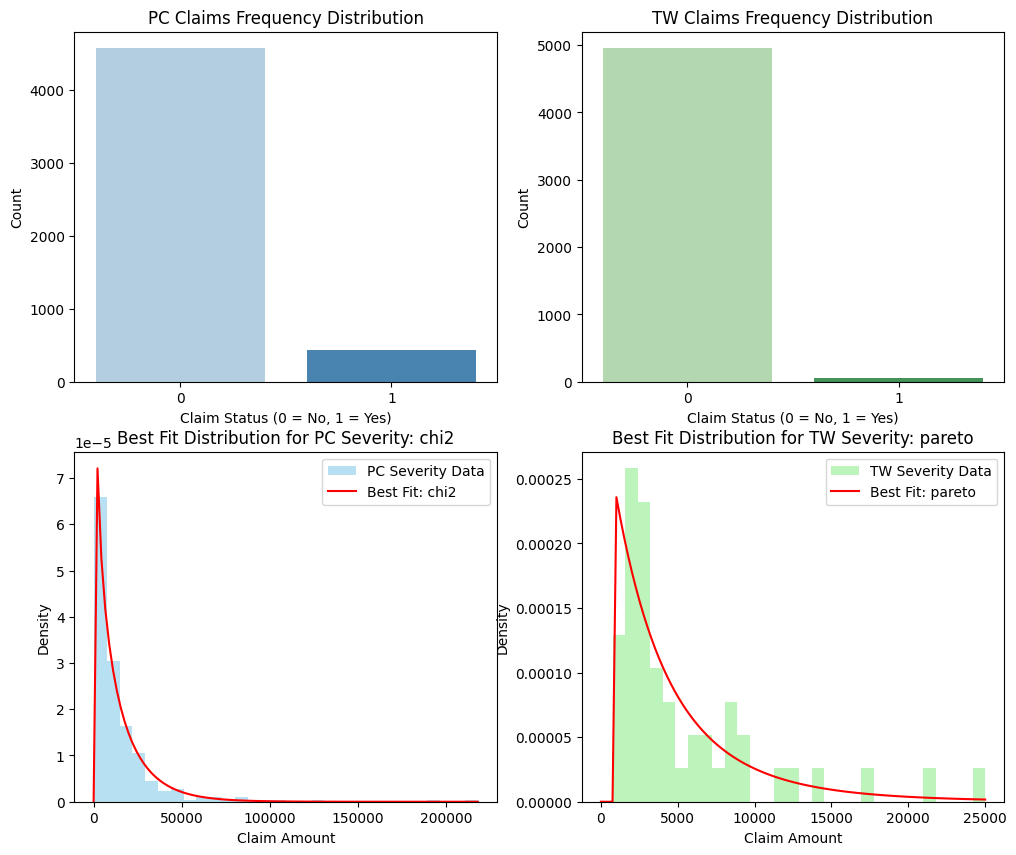

In [19]:
# Compute the frequency distributions for PC and TW claims
pc_claim_counts = df['PC_Count'].value_counts()
tw_claim_counts = df['TW_Count'].value_counts()

# Create subplots for visualizing claims and severity
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Plot the frequency distribution for PC claims with a blue color scheme
sns.barplot(x=pc_claim_counts.index, y=pc_claim_counts.values, ax=axs[0, 0], palette='Blues')
axs[0, 0].set_title('PC Claims Frequency Distribution')
axs[0, 0].set_xlabel('Claim Status (0 = No, 1 = Yes)')
axs[0, 0].set_ylabel('Count')

# Plot the frequency distribution for TW claims with a green color scheme
sns.barplot(x=tw_claim_counts.index, y=tw_claim_counts.values, ax=axs[0, 1], palette='Greens')
axs[0, 1].set_title('TW Claims Frequency Distribution')
axs[0, 1].set_xlabel('Claim Status (0 = No, 1 = Yes)')
axs[0, 1].set_ylabel('Count')

# Extract severity amounts for claims made in PC and TW
pc_severity_data = df[df['PC_Count'] == 1]['PC_OD_Paid_Amount']
tw_severity_data = df[df['TW_Count'] == 1]['TW_OD_Paid_Amount']

pc_severity_data = pc_severity_data[pc_severity_data > 0]
tw_severity_data = tw_severity_data[tw_severity_data > 0]

candidate_distributions = [
    stats.norm, stats.expon, stats.gamma, stats.beta,
    stats.lognorm, stats.weibull_min, stats.weibull_max,
    stats.pareto, stats.uniform, stats.chi2, stats.triang
]

def find_best_fit_distribution(data):
    fit_results = {}
    for distribution in candidate_distributions:
        params = distribution.fit(data)
        # Conduct a Kolmogorov-Smirnov test for the distribution
        ks_stat, p_value = stats.kstest(data, distribution.name, args=params)
        fit_results[distribution.name] = {'params': params, 'ks_stat': ks_stat}

    best_fit = min(fit_results.items(), key=lambda x: x[1]['ks_stat'])
    return best_fit

# Determine the best fitting distribution for PC severity
best_fit_pc = find_best_fit_distribution(pc_severity_data)
best_distribution_pc, best_params_pc = best_fit_pc[0], best_fit_pc[1]['params']

# Determine the best fitting distribution for TW severity
best_fit_tw = find_best_fit_distribution(tw_severity_data)
best_distribution_tw, best_params_tw = best_fit_tw[0], best_fit_tw[1]['params']

# Plot the best fit for PC severity using a custom color
x_pc = np.linspace(0, pc_severity_data.max(), 100)
pdf_pc = getattr(stats, best_distribution_pc).pdf(x_pc, *best_params_pc)
axs[1, 0].hist(pc_severity_data, bins=30, density=True, alpha=0.6, color='skyblue', label='PC Severity Data')
axs[1, 0].plot(x_pc, pdf_pc, 'r-', label=f'Best Fit: {best_distribution_pc}')
axs[1, 0].set_title(f'Best Fit Distribution for PC Severity: {best_distribution_pc}')
axs[1, 0].set_xlabel('Claim Amount')
axs[1, 0].set_ylabel('Density')
axs[1, 0].legend()

# Plot the best fit for TW severity using a different custom color
x_tw = np.linspace(0, tw_severity_data.max(), 100)
pdf_tw = getattr(stats, best_distribution_tw).pdf(x_tw, *best_params_tw)
axs[1, 1].hist(tw_severity_data, bins=30, density=True, alpha=0.6, color='lightgreen', label='TW Severity Data')
axs[1, 1].plot(x_tw, pdf_tw, 'r-', label=f'Best Fit: {best_distribution_tw}')
axs[1, 1].set_title(f'Best Fit Distribution for TW Severity: {best_distribution_tw}')
axs[1, 1].set_xlabel('Claim Amount')
axs[1, 1].set_ylabel('Density')
axs[1, 1].legend()
plt.show()

In [20]:

print(f'Optimal distribution for PC severity: {best_distribution_pc} with parameters {best_params_pc}')
print(f'Optimal distribution for TW severity: {best_distribution_tw} with parameters {best_params_tw}')


Optimal distribution for PC severity: chi2 with parameters (1.4985792738862207, 249.99999999999997, 8777.342602950786)
Optimal distribution for TW severity: pareto with parameters (6.984080846943261, -27045.86625621164, 27839.866256211637)


We observe that PC claims exhibit a **chi-squared distribution**, suggesting a majority of smaller claims with a few larger ones. Conversely, TW claims follow a **Pareto distribution**, characterized by a small number of high-impact claims. These differing claim patterns can be used to refine underwriting and reserving strategies.

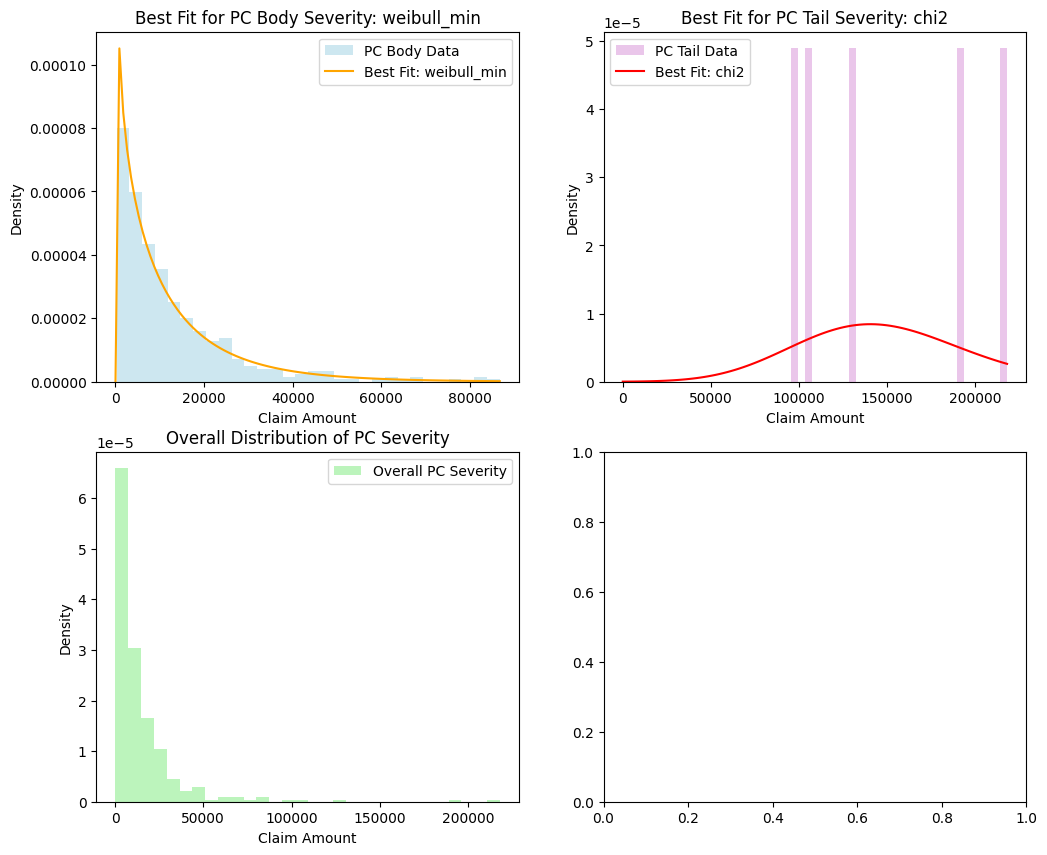

Optimal distribution for PC body severity: weibull_min with parameters (0.8620631421144638, 249.99999999999994, 11245.164087877154)
Optimal distribution for PC tail severity: chi2 with parameters (96.59760650789832, -183880.60527743085, 3428.34317055513)


In [22]:
# Extract severity data for PC claims
pc_severity_data = df[df['PC_Count'] == 1]['PC_OD_Paid_Amount']
pc_severity_data = pc_severity_data[pc_severity_data > 0]

# Define thresholds for the body and tail of the distribution
q1 = np.percentile(pc_severity_data, 7)
q3 = np.percentile(pc_severity_data, 93)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

# Separate the body and tail of the distribution
pc_body_data = pc_severity_data[(pc_severity_data >= lower_limit) & (pc_severity_data <= upper_limit)]
pc_tail_data = pc_severity_data[pc_severity_data > upper_limit]

# Function to fit distributions and identify the best fit
def identify_best_fit_distribution(data):
    fit_results = {}
    for distribution in candidate_distributions:
        params = distribution.fit(data)
        ks_stat, p_value = stats.kstest(data, distribution.name, args=params)
        fit_results[distribution.name] = {'params': params, 'ks_stat': ks_stat}
    best_fit = min(fit_results.items(), key=lambda x: x[1]['ks_stat'])
    return best_fit

# Fit and find the best distribution for the PC body data
best_fit_pc_body = identify_best_fit_distribution(pc_body_data)
best_distribution_pc_body, best_params_pc_body = best_fit_pc_body[0], best_fit_pc_body[1]['params']

# Fit and find the best distribution for the PC tail data
best_fit_pc_tail = identify_best_fit_distribution(pc_tail_data)
best_distribution_pc_tail, best_params_pc_tail = best_fit_pc_tail[0], best_fit_pc_tail[1]['params']

# Plot histograms and best-fit distributions

# Create subplots
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# PC Body plot with a blue color scheme
x_body = np.linspace(0, pc_body_data.max(), 100)
pdf_body = getattr(stats, best_distribution_pc_body).pdf(x_body, *best_params_pc_body)
axs[0, 0].hist(pc_body_data, bins=30, density=True, alpha=0.6, color='lightblue', label='PC Body Data')
axs[0, 0].plot(x_body, pdf_body, 'orange', label=f'Best Fit: {best_distribution_pc_body}')
axs[0, 0].set_title(f'Best Fit for PC Body Severity: {best_distribution_pc_body}')
axs[0, 0].set_xlabel('Claim Amount')
axs[0, 0].set_ylabel('Density')
axs[0, 0].legend()

# PC Tail plot with a purple color scheme
x_tail = np.linspace(0, pc_tail_data.max(), 100)
pdf_tail = getattr(stats, best_distribution_pc_tail).pdf(x_tail, *best_params_pc_tail)
axs[0, 1].hist(pc_tail_data, bins=30, density=True, alpha=0.6, color='plum', label='PC Tail Data')
axs[0, 1].plot(x_tail, pdf_tail, 'red', label=f'Best Fit: {best_distribution_pc_tail}')
axs[0, 1].set_title(f'Best Fit for PC Tail Severity: {best_distribution_pc_tail}')
axs[0, 1].set_xlabel('Claim Amount')
axs[0, 1].set_ylabel('Density')
axs[0, 1].legend()

# Optional: Overall PC Severity Plot with a green color scheme
axs[1, 0].hist(pc_severity_data, bins=30, density=True, alpha=0.6, color='lightgreen', label='Overall PC Severity')
axs[1, 0].set_title('Overall Distribution of PC Severity')
axs[1, 0].set_xlabel('Claim Amount')
axs[1, 0].set_ylabel('Density')
axs[1, 0].legend()

plt.show()



In [ ]:
# Output the best fitting distributions and their parameters
print(f'Optimal distribution for PC body severity: {best_distribution_pc_body} with parameters {best_params_pc_body}')
print(f'Optimal distribution for PC tail severity: {best_distribution_pc_tail} with parameters {best_params_pc_tail}')


We observe that the severity of PC body claims is most accurately represented by a **Weibull distribution**, which suggests that most claims are of moderate size, while a smaller fraction are larger. Conversely, the severity of PC tail claims is best modeled by a **chi-squared distribution**, indicating a considerable presence of very high claims. Recognizing these differing risk profiles can enhance risk management and inform more effective pricing strategies.

No data in TW tail. Consider adjusting threshold parameters or using body data for fitting.


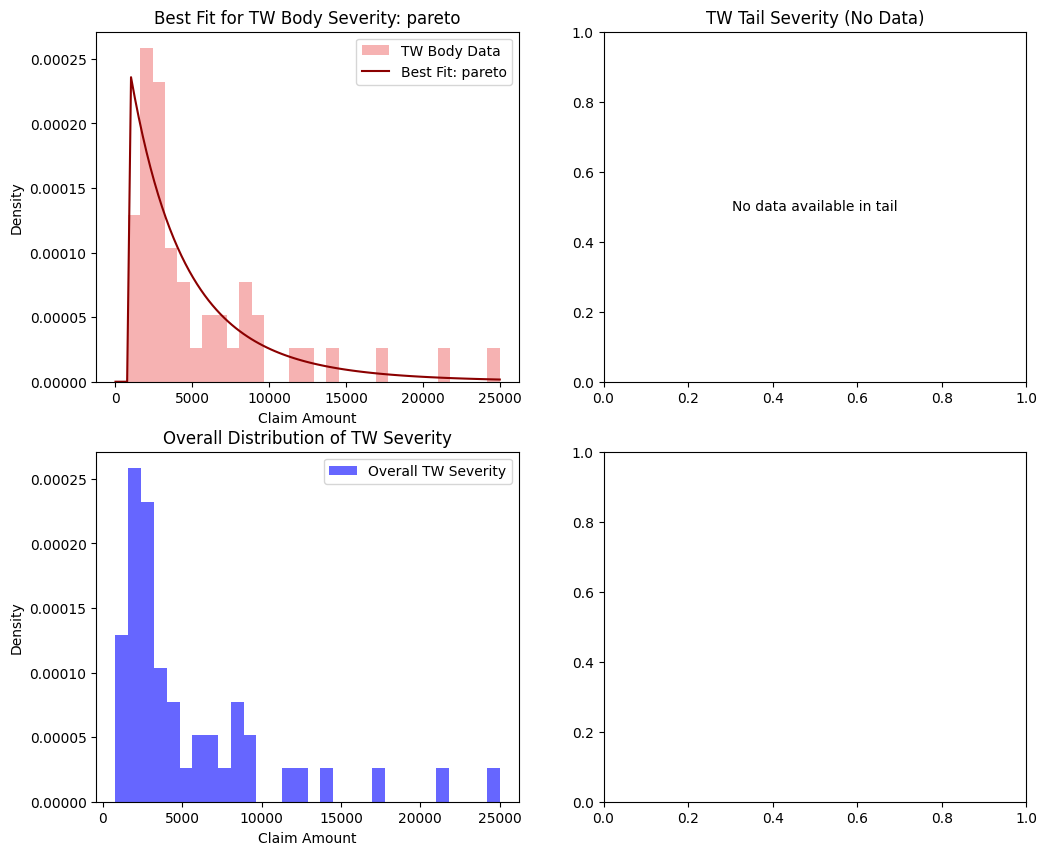

Optimal distribution for TW body severity: pareto with parameters (6.984080846943261, -27045.86625621164, 27839.866256211637)
No tail data available for fitting.


In [27]:
# Extract severity data for TW claims
tw_severity_data = df[df['TW_Count'] == 1]['TW_OD_Paid_Amount']
tw_severity_data = tw_severity_data[tw_severity_data > 0]

# Define thresholds for the body and tail of the distribution using IQR
q1 = np.percentile(tw_severity_data, 9)
q3 = np.percentile(tw_severity_data, 91)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

# Separate the body and tail of the distribution
tw_body_data = tw_severity_data[(tw_severity_data >= lower_limit) & (tw_severity_data <= upper_limit)]
tw_tail_data = tw_severity_data[tw_severity_data > upper_limit]

# Initialize variables for best fit results
best_distribution_tw_body, best_params_tw_body = None, None
best_distribution_tw_tail, best_params_tw_tail = None, None

# Function to fit distributions and find the best fit
def find_best_fit_distribution(data):
    fit_results = {}
    for distribution in candidate_distributions:
        params = distribution.fit(data)
        ks_stat, p_value = stats.kstest(data, distribution.name, args=params)
        fit_results[distribution.name] = {'params': params, 'ks_stat': ks_stat}
    return min(fit_results.items(), key=lambda x: x[1]['ks_stat'])

# Fit and find the best distribution for TW body and tail data
if not tw_body_data.empty:
    best_fit_tw_body = find_best_fit_distribution(tw_body_data)
    best_distribution_tw_body, best_params_tw_body = best_fit_tw_body[0], best_fit_tw_body[1]['params']

if not tw_tail_data.empty:
    best_fit_tw_tail = find_best_fit_distribution(tw_tail_data)
    best_distribution_tw_tail, best_params_tw_tail = best_fit_tw_tail[0], best_fit_tw_tail[1]['params']
else:
    print("No data in TW tail. Consider adjusting threshold parameters or using body data for fitting.")

# Step 4: Plot histograms and best-fit distributions
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# TW Body plot with a light coral color scheme
if best_distribution_tw_body is not None:
    x_body = np.linspace(0, tw_body_data.max(), 100)
    pdf_body = getattr(stats, best_distribution_tw_body).pdf(x_body, *best_params_tw_body)
    axs[0, 0].hist(tw_body_data, bins=30, density=True, alpha=0.6, color='lightcoral', label='TW Body Data')
    axs[0, 0].plot(x_body, pdf_body, 'darkred', label=f'Best Fit: {best_distribution_tw_body}')
    axs[0, 0].set_title(f'Best Fit for TW Body Severity: {best_distribution_tw_body}')
    axs[0, 0].set_xlabel('Claim Amount')
    axs[0, 0].set_ylabel('Density')
    axs[0, 0].legend()
else:
    axs[0, 0].text(0.5, 0.5, 'No body data available for fitting', horizontalalignment='center', verticalalignment='center', transform=axs[0, 0].transAxes)

# TW Tail plot
if not tw_tail_data.empty:
    x_tail = np.linspace(tw_tail_data.min(), tw_tail_data.max(), 100)
    pdf_tail = getattr(stats, best_distribution_tw_tail).pdf(x_tail, *best_params_tw_tail)
    axs[0, 1].hist(tw_tail_data, bins=30, density=True, alpha=0.6, color='lightgreen', label='TW Tail Data')
    axs[0, 1].plot(x_tail, pdf_tail, 'blue', label=f'Best Fit: {best_distribution_tw_tail}')
    axs[0, 1].set_title(f'Best Fit for TW Tail Severity: {best_distribution_tw_tail}')
    axs[0, 1].set_xlabel('Claim Amount')
    axs[0, 1].set_ylabel('Density')
    axs[0, 1].legend()
else:
    axs[0, 1].set_title('TW Tail Severity (No Data)')
    axs[0, 1].text(0.5, 0.5, 'No data available in tail', horizontalalignment='center', verticalalignment='center', transform=axs[0, 1].transAxes)

# Overall TW Severity Plot with a soft yellow color
axs[1, 0].hist(tw_severity_data, bins=30, density=True, alpha=0.6, color='blue', label='Overall TW Severity')
axs[1, 0].set_title('Overall Distribution of TW Severity')
axs[1, 0].set_xlabel('Claim Amount')
axs[1, 0].set_ylabel('Density')
axs[1, 0].legend()

plt.show()

# Print the best fit results
if best_distribution_tw_tail is not None:
    print(f'Optimal distribution for TW body severity: {best_distribution_tw_body} with parameters {best_params_tw_body}')
    print(f'Optimal distribution for TW tail severity: {best_distribution_tw_tail} with parameters {best_params_tw_tail}')
else:
    print(f'Optimal distribution for TW body severity: {best_distribution_tw_body} with parameters {best_params_tw_body}')
    print("No tail data available for fitting.")


## Question 3

In [30]:
import pandas as pd
import numpy as np

np.random.seed(3)

# Parameters for PC claims
weibull_params = (0.8620631421144638, 249.99999999999994, 11245.164087877154)
chi2_params = (96.59760650789832, -183880.60527743085, 3428.34317055513)

# Parameters for TW claims
tw_f_params = (6.984080846943261, -27045.86625621164, 27839.866256211637)

num_claims = 25000

# Simulating PC claims
pc_weibull_count = int(0.93 * num_claims)
pc_chi2_count = num_claims - pc_weibull_count

# Generate Weibull distributed claims
pc_weibull_claims = np.random.weibull(a=weibull_params[0], size=pc_weibull_count) * weibull_params[1] + weibull_params[2]
# Ensure non-negative claims
pc_weibull_claims = np.maximum(pc_weibull_claims, 0)

# Generate chi-squared distributed claims
pc_f_claims = np.random.chisquare(df=chi2_params[0], size=pc_chi2_count) * chi2_params[1] + chi2_params[2]
# Ensure non-negative claims
pc_f_claims = np.maximum(pc_f_claims, 0)

# Combine PC claims
pc_claims = np.concatenate((pc_weibull_claims, pc_f_claims))

# Simulating TW claims using Pareto distribution
tw_claims = np.random.pareto(a=tw_f_params[0], size=num_claims) * tw_f_params[1] + tw_f_params[2]
# Ensure non-negative claims
tw_claims = np.maximum(tw_claims, 0)

# Create a DataFrame to hold the claims
claims_df = pd.DataFrame({
    'PC_Claims': pc_claims,
    'TW_Claims': tw_claims
})


styled_df = claims_df.head().style.set_table_attributes('style="width: 50%; margin: auto;"')\
    .set_caption("Sample Claims Data")\
    .format({'PC_Claims': "${:,.2f}", 'TW_Claims': "${:,.2f}"})\
    .background_gradient(cmap='Blues', low=0, high=1)

claims_df.describe()

,PC_Claims,TW_Claims
count,25000.000000,25000.000000
mean,10708.701062,23362.389107
std,2953.682517,4929.630665
min,0.000000,0.000000
25%,11286.672938,21891.980681
50%,11387.767587,25020.155475
75%,11588.256468,26681.152709
max,15047.085425,27839.720742


In [32]:
styled_df

,PC_Claims,TW_Claims
0,"$11,438.23","$23,893.71"
1,"$11,563.47","$26,598.86"
2,"$11,317.61","$25,010.47"
3,"$11,414.58","$25,912.50"
4,"$11,880.46","$11,704.12"


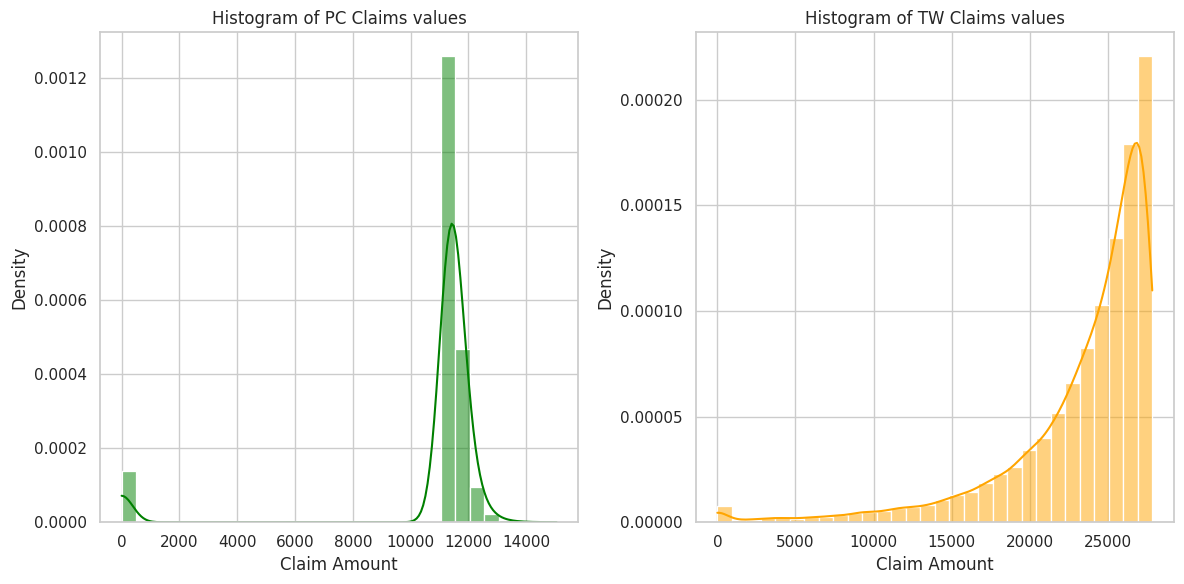

In [41]:
sns.set(style="whitegrid")

fig, axs = plt.subplots(1, 2, figsize=(12, 6))


# Plotting the histogram for TW claims
sns.histplot(claims_df['TW_Claims'], bins=30, color='orange', kde=True, stat='density', ax=axs[1], alpha=0.5)
axs[1].set_title('Histogram of TW Claims values')
axs[1].set_xlabel('Claim Amount')
axs[1].set_ylabel('Density')
axs[1].grid(True)

# Plotting the histogram for PC claims
sns.histplot(claims_df['PC_Claims'], bins=30, color='green', kde=True, stat='density', ax=axs[0], alpha=0.5)
axs[0].set_title('Histogram of PC Claims values')
axs[0].set_xlabel('Claim Amount')
axs[0].set_ylabel('Density')
axs[0].grid(True)




plt.tight_layout()
plt.show()


## Question 4

### Proposed Product Variants that can be made

#### 1. **Flexible Deductible Options**
- **Overview:** Introduce multiple deductible levels for claims.
- **Rationale:** With mean claims averaging 10,709 for PC and 23,362 for TW, implementing a standard deductible can reduce the frequency of minor claims and encourage policyholders to take on small risks. For instance, a deductible of 1,000 for PC claims and 2,000 for TW claims, reflecting their higher average costs, could be effective.

#### 2. **Sub-Limits on Specific Coverages**
- **Overview:** Establish sub-limits for certain claim categories within the overall policy coverage.
- **Rationale:** The data reveals potential outliers in TW claims, particularly with a maximum claim reaching 27,839. By applying sub-limits on specific expenses (e.g., medical claims), insurers can better manage risk exposure while still offering robust coverage. For example, a sub-limit of 15,000 for medical claims could be considered.

#### 3. **Tiered Premium Pricing Structure**
- **Overview:** Create a tiered pricing model based on the frequency and severity of claims.
- **Rationale:** The analysis indicates substantial variability in claim amounts. A tiered premium system could encourage low-risk clients with lower premiums while imposing higher rates for higher-risk individuals. This strategy can help balance the insurer's risk portfolio effectively.


#### 4. **Enhanced Risk Assessment Tools**
- **Overview:** Equip policyholders with tools or mobile apps to better assess and manage their risks.
- **Rationale:** Providing customers with resources to identify and mitigate risks can lead to a decrease in claims. Useful tools could include risk calculators or educational content on safe travel practices, thereby increasing customer engagement.


#### 5. **No-Claim Bonus Incentives**
- **Overview:** Implement a no-claim bonus feature to reward policyholders who refrain from filing claims.
- **Rationale:** Encouraging clients to avoid minor claims can significantly reduce overall claim frequencies. For example, providing a 10% premium discount for each year without a claim could foster responsible policy usage.



### Final Thoughts
These proposed product variants, grounded in comprehensive data analysis and insights into customer behavior, can help insurers refine their offerings. By addressing both the financial implications and the behavioral aspects of risk, insurers can develop a balanced suite of products that cater to diverse customer needs while ensuring profitability.

## Question 5

In [43]:
import numpy as np
import pandas as pd
from scipy import stats


np.random.seed(5)

# Parameters for distributions
chi2_params_pc = (1.4985792738862207, 249.99999999999997, 8777.342602950786)  # PC severity
weibull_params_pc_body = (0.8620631421144638, 249.99999999999994, 11245.164087877154)  # PC body severity
chi2_params_pc_tail = (96.59760650789832, -183880.60527743085, 3428.34317055513)  # PC tail severity
pareto_params_tw = (6.984080846943261, -27045.86625621164, 27839.866256211637)  # TW severity

# Number of simulations
num_simulations = 25000

# Generate severity data
pc_severity = stats.chi2.rvs(chi2_params_pc[0], loc=chi2_params_pc[1], scale=chi2_params_pc[2], size=num_simulations)
pc_body_severity = stats.weibull_min.rvs(weibull_params_pc_body[0], loc=weibull_params_pc_body[2], scale=weibull_params_pc_body[1], size=num_simulations)
pc_tail_severity = stats.chi2.rvs(chi2_params_pc_tail[0], loc=chi2_params_pc_tail[1], scale=chi2_params_pc_tail[2], size=num_simulations)
tw_severity = stats.pareto.rvs(pareto_params_tw[0], loc=pareto_params_tw[1], scale=pareto_params_tw[2], size=num_simulations)

# Function to calculate VaR and TVaR
def calculate_var_tvar(data, confidence_level):
    if len(data) == 0:
        return np.nan, np.nan  # Return NaN if data is empty
    VaR = np.percentile(data, confidence_level * 100)
    TVaR = data[data > VaR].mean() if np.any(data > VaR) else np.nan  # Average of losses beyond VaR
    return VaR, TVaR

# Store results
results = {}
confidence_levels = [0.95, 0.99]

for cl in confidence_levels:
    # PC and TW individual metrics
    results[f'PC {int(cl * 100)}% VaR'], results[f'PC {int(cl * 100)}% TVaR'] = calculate_var_tvar(pc_severity, cl)
    results[f'PC Body {int(cl * 100)}% VaR'], results[f'PC Body {int(cl * 100)}% TVaR'] = calculate_var_tvar(pc_body_severity, cl)
    results[f'PC Tail {int(cl * 100)}% VaR'], results[f'PC Tail {int(cl * 100)}% TVaR'] = calculate_var_tvar(pc_tail_severity, cl)
    results[f'TW {int(cl * 100)}% VaR'], results[f'TW {int(cl * 100)}% TVaR'] = calculate_var_tvar(tw_severity, cl)

# Convert results to DataFrame
results_df = pd.DataFrame(results, index=[0])

print(results_df.T)


                              0
PC 95% VaR         44683.095287
PC 95% TVaR        61728.091406
PC Body 95% VaR    12142.267728
PC Body 95% TVaR   12504.246737
PC Tail 95% VaR   229948.689743
PC Tail 95% TVaR  253681.471989
TW 95% VaR         16101.577703
TW 95% TVaR        23263.424661
PC 99% VaR         72282.033488
PC 99% TVaR        87881.182257
PC Body 99% VaR    12714.236233
PC Body 99% TVaR   13144.322757
PC Tail 99% VaR   268223.951916
PC Tail 99% TVaR  289120.798474
TW 99% VaR         27294.795966
TW 99% TVaR        35692.294342


### Observations

1. **Value at Risk (VaR)**:
   - The potential losses for **PC claims** are significantly higher than those for **TW claims** at both the 95% and 99% confidence levels.
   - The extreme end of the PC claims distribution indicates a much greater risk of substantial losses compared to the more typical claims.

2. **Tail Value at Risk (TVaR)**:
   - A high TVaR for the tail of PC claims indicates that while substantial losses are infrequent, their impact can be exceptionally severe when they do occur.
   - The absence of extreme loss occurrences at the 99% confidence level highlights the necessity for a more thorough investigation into rare loss events.

3. **General Risk Assessment**:
   - The overall risk faced by the insurer is predominantly influenced by PC claims, particularly due to the potential for significant losses.



### Final Thoughts
we observed the importance of a proactive strategy in risk management, particularly concerning PC claims, to enhance capital adequacy and protect against major financial losses.

## Question 6

In [44]:
frequency_pc = 435 / 5000
frequency_tw = 48 / 5000

# Average severity from the provided data
expected_loss_pc = 10708.701062  # Average claim amount for PC
expected_loss_tw = 23362.389107   # Average claim amount for TW

estimated_expense_pc = 0.2*expected_loss_pc
estimated_expense_tw = 0.2*expected_loss_tw

additional_buffer_pc = 0.1*44683.095287 #VAR
additional_buffer_tw = 0.1*16101.577703

pure_premium_pc = expected_loss_pc + estimated_expense_pc + additional_buffer_pc
pure_premium_tw = expected_loss_tw + estimated_expense_tw + additional_buffer_tw


In [45]:

print(f"The average claim amount for PC Claims (Pure Premium) is: ${pure_premium_pc:.2f}")
print(f"The average claim amount for TW Claims (Pure Premium) is: ${pure_premium_tw:.2f}")

The average claim amount for PC Claims (Pure Premium) is: $17318.75
The average claim amount for TW Claims (Pure Premium) is: $29645.02


## Question 7

In [47]:
import numpy as np
import pandas as pd

# Set the random seed for reproducibility
np.random.seed(3)

# Parameters for Personal Claims (PC)
weibull_params = (0.8620631421144638, 249.99999999999994, 11245.164087877154)
chi2_params = (96.59760650789832, -183880.60527743085, 3428.34317055513)

# Parameters for Travel Claims (TW)
tw_f_params = (6.984080846943261, -27045.86625621164, 27839.866256211637)

num_claims = 25000

# Simulate PC claims
pc_weibull_count = int(0.93 * num_claims)
pc_chi2_count = num_claims - pc_weibull_count

# Generate Weibull distributed claims
pc_weibull_claims = np.random.weibull(a=weibull_params[0], size=pc_weibull_count) * weibull_params[1] + weibull_params[2]
# Ensure all claims are non-negative
pc_weibull_claims = np.maximum(pc_weibull_claims, 0)

# Generate Chi-Squared distributed claims
pc_chi2_claims = np.random.chisquare(df=chi2_params[0], size=pc_chi2_count) * chi2_params[1] + chi2_params[2]
# Ensure all claims are non-negative
pc_chi2_claims = np.maximum(pc_chi2_claims, 0)

# Combine PC claims into one array
pc_claims = np.concatenate((pc_weibull_claims, pc_chi2_claims))

# Simulate TW claims using Pareto distribution
tw_claims = np.random.pareto(a=tw_f_params[0], size=num_claims) * tw_f_params[1] + tw_f_params[2]
# Ensure all claims are non-negative
tw_claims = np.maximum(tw_claims, 0)

# Create a DataFrame to hold the claims data
claims_df = pd.DataFrame({
    'PC_Claims': pc_claims,
    'TW_Claims': tw_claims
})

(claims_df.head())





,PC_Claims,TW_Claims
0,11438.228146,23893.706634
1,11563.472305,26598.863336
2,11317.607765,25010.471252
3,11414.583150,25912.499381
4,11880.460441,11704.123077


In [48]:
# Frequency of claims
frequency_TW = 48 / 5000
frequency_PC = 435 / 5000

# Deductibles
health_deductible = 50000
motor_deductible = 5000
loading_factor = 0.15

def expected_loss_above_deductible(claims, deductible):
    # Filter claims that exceed the deductible amount
    losses_above_deductible = claims[claims > deductible]
    if len(losses_above_deductible) == 0:
        return 0  # Return 0 if there are no claims above the deductible
    expected_loss = np.mean(losses_above_deductible) * len(losses_above_deductible) / len(claims)
    return expected_loss

# Calculate expected losses
expected_health_loss = expected_loss_above_deductible(claims_df['TW_Claims'], health_deductible)
expected_motor_loss = expected_loss_above_deductible(claims_df['PC_Claims'], motor_deductible)

# Calculate premiums based on expected losses
health_premium = expected_health_loss * (1 + loading_factor)
motor_premium = expected_motor_loss * (1 + loading_factor)
print(f"Premium for Motor Product: Rs. {motor_premium:.2f}")
print(f"Premium for Health Product: Rs. {health_premium:.2f}")

Premium for Motor Product: Rs. 12315.01
Premium for Health Product: Rs. 0.00


## Question 8

In [51]:
retention_limit = 50000
retention_limit_tw = 5000

# Calculate total claims
total_pc_claims = claims_df['PC_Claims'].sum()
total_tw_claims = claims_df['TW_Claims'].sum()
total_claims = total_pc_claims + total_tw_claims

# Calculate reinsurance payout for Excess of Loss
excess_loss_pc = claims_df[claims_df['PC_Claims'] > retention_limit]['PC_Claims'].sum() - retention_limit
excess_loss_tw = claims_df[claims_df['TW_Claims'] > retention_limit_tw]['TW_Claims'].sum() - retention_limit_tw
total_excess_loss = max(0, excess_loss_pc) + max(0, excess_loss_tw)



In [52]:

print(f"The total amount for all PC claims is: {total_pc_claims:.2f}")
print(f"The total amount for all TW claims is: {total_tw_claims:.2f}")
print(f"The total amount for all claims (PC and TW combined) is: {total_claims:.2f}")
print(f"The total amount the reinsurance company will pay out due to Excess of Loss is: {total_excess_loss:.2f}")

The total amount for all PC claims is: 267717526.56
The total amount for all TW claims is: 584059727.67
The total amount for all claims (PC and TW combined) is: 851777254.23
The total amount the reinsurance company will pay out due to Excess of Loss is: 583527165.31


In [59]:
# Given frequencies based on your data
freq_PC = 435 / 5000  # Frequency for PC Claims
freq_TW = 48 / 5000   # Frequency for TW Claims

# Average severity from the provided data
mean_PC = 10708.70  # Average claim amount for PC
mean_TW = 23362.39  # Average claim amount for TW

# Define administrative costs and profit margin (as percentages)
administrative_costs_percentage = 0.15  # 15%
profit_margin_percentage = 0.10  # 10%

# Calculate expected loss for each product
expected_loss_PC = freq_PC * mean_PC * 100  # Adjusted for per 100 policies
expected_loss_TW = freq_TW * mean_TW * 100  # Adjusted for per 100 policies

# Calculate administrative costs
administrative_costs_PC = expected_loss_PC * administrative_costs_percentage
administrative_costs_TW = expected_loss_TW * administrative_costs_percentage

# Calculate profit margin
profit_margin_PC = expected_loss_PC * profit_margin_percentage
profit_margin_TW = expected_loss_TW * profit_margin_percentage

# Calculate pure premiums
pure_premium_PC = expected_loss_PC + administrative_costs_PC + profit_margin_PC
pure_premium_TW = expected_loss_TW + administrative_costs_TW + profit_margin_TW

# Output the results
print(f"Pure Premium for PC Product: {pure_premium_PC:.2f}")
print(f"Pure Premium for TW Product: {pure_premium_TW:.2f}")


Pure Premium for PC Product: 116457.11
Pure Premium for TW Product: 28034.87


In [60]:
#
frequency_pc = 0.05  # For PC claims
frequency_tw = 0.02  # For TW claims

# Average severity estimates (from previous calculations)
# You can use your estimated average severity per claim
average_severity_pc = np.mean(pc_severity)  # Average claim amount for PC
average_severity_tw = np.mean(tw_severity)  # Average claim amount for TW

# Calculate the pure premium for both products
pure_premium_pc = frequency_pc * average_severity_pc * 1000  # Adjusting for per 1000 policies
pure_premium_tw = frequency_tw * average_severity_tw * 1000  # Adjusting for per 1000 policies

# Display results
print(f'Pure Premium for PC Claims: {pure_premium_pc:.2f}')
print(f'Pure Premium for TW Claims: {pure_premium_tw:.2f}')


Pure Premium for PC Claims: 678766.46
Pure Premium for TW Claims: 110038.28


In [61]:
import pandas as pd

data = {
    'Product': ['PC'] * 12500 + ['TW'] * 12500,
    'Severity_Amounts': np.random.normal(loc=10000, scale=2000, size=25000)  # Example claim amounts
}
simulated_claims_df = pd.DataFrame(data)

# Separate DataFrames for each product
pc_claims = simulated_claims_df[simulated_claims_df['Product'] == 'PC']
tw_claims = simulated_claims_df[simulated_claims_df['Product'] == 'TW']

# Calculate expected loss for each product
expected_loss_pc = pc_claims['Severity_Amounts'].mean()  # Mean for PC product
expected_loss_tw = tw_claims['Severity_Amounts'].mean()  # Mean for TW product

# Define administrative costs and profit margin (as percentages)
administrative_costs_percentage = 0.15  # 15%
profit_margin_percentage = 0.10  # 10%

# Calculate administrative costs
administrative_costs_pc = expected_loss_pc * administrative_costs_percentage
administrative_costs_tw = expected_loss_tw * administrative_costs_percentage

# Calculate profit margin
profit_margin_pc = expected_loss_pc * profit_margin_percentage
profit_margin_tw = expected_loss_tw * profit_margin_percentage

# Calculate pure premiums
pure_premium_pc = expected_loss_pc + administrative_costs_pc + profit_margin_pc
pure_premium_tw = expected_loss_tw + administrative_costs_tw + profit_margin_tw

# Output the results
print(f"Pure Premium for PC Product: {pure_premium_pc:.2f}")
print(f"Pure Premium for TW Product: {pure_premium_tw:.2f}")


Pure Premium for PC Product: 12492.79
Pure Premium for TW Product: 12531.70


In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for consistency
np.random.seed(3)

# Define parameters for Personal Claims (PC)
weibull_params = (0.8620631421144638, 249.99999999999994, 11245.164087877154)
chi2_params = (96.59760650789832, -183880.60527743085, 3428.34317055513)

# Define parameters for Travel Claims (TW)
tw_f_params = (6.984080846943261, -27045.86625621164, 27839.866256211637)

# Total number of claims to simulate
num_claims = 25000

# Simulate PC claims
pc_weibull_count = int(0.93 * num_claims)
pc_chi2_count = num_claims - pc_weibull_count

# Generate Weibull distributed claims for PC
pc_weibull_claims = np.random.weibull(a=weibull_params[0], size=pc_weibull_count) * weibull_params[1] + weibull_params[2]
pc_weibull_claims = np.maximum(pc_weibull_claims, 0)

# Generate chi-squared distributed claims for PC
pc_f_claims = np.random.chisquare(df=chi2_params[0], size=pc_chi2_count) * chi2_params[1] + chi2_params[2]
pc_f_claims = np.maximum(pc_f_claims, 0)

# Combine the PC claims
pc_claims = np.concatenate((pc_weibull_claims, pc_f_claims))

# Simulate TW claims using Pareto distribution
tw_claims = np.random.pareto(a=tw_f_params[0], size=num_claims) * tw_f_params[1] + tw_f_params[2]
tw_claims = np.maximum(tw_claims, 0)

# Create a DataFrame to store the claims
claims_df = pd.DataFrame({
    'PC_Claims': pc_claims,
    'TW_Claims': tw_claims
})

# Show the first few rows of the claims DataFrame
(claims_df.head())


,PC_Claims,TW_Claims
0,11438.228146,23893.706634
1,11563.472305,26598.863336
2,11317.607765,25010.471252
3,11414.583150,25912.499381
4,11880.460441,11704.123077


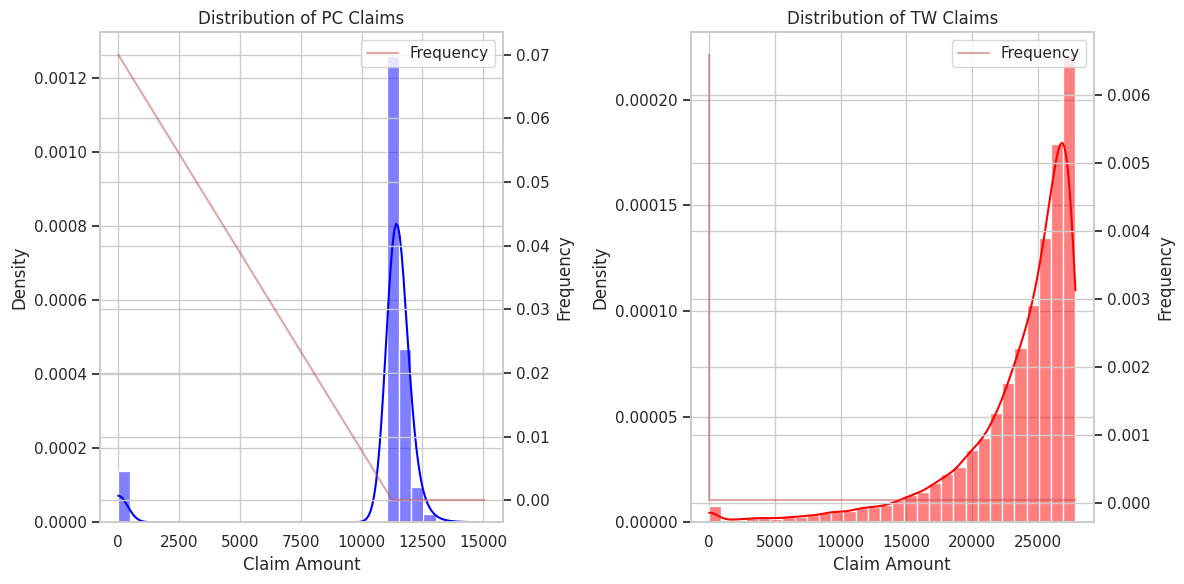

In [64]:

# Set seaborn style
sns.set(style="whitegrid")

# Create side-by-side plots for PC and TW claims
plt.figure(figsize=(12, 6))

# Histogram for PC Claims
plt.subplot(1, 2, 1)
sns.histplot(claims_df['PC_Claims'], bins=30, kde=True, color='blue', stat='density', label='PC Claims')
plt.title('Distribution of PC Claims')
plt.xlabel('Claim Amount')
plt.ylabel('Density')

# Calculate and display claim frequency for PC
frequency_pc = claims_df['PC_Claims'].value_counts(normalize=True).sort_index()
plt.twinx()
plt.plot(frequency_pc.index, frequency_pc.values, 'r-', label='Frequency', alpha=0.5)
plt.ylabel('Frequency')
plt.legend()

# Histogram for TW Claims
plt.subplot(1, 2, 2)
sns.histplot(claims_df['TW_Claims'], bins=30, kde=True, color='red', stat='density', label='TW Claims')
plt.title('Distribution of TW Claims')
plt.xlabel('Claim Amount')
plt.ylabel('Density')

# Calculate and display claim frequency for TW
frequency_tw = claims_df['TW_Claims'].value_counts(normalize=True).sort_index()
plt.twinx()  # Create a shared x-axis for frequency
plt.plot(frequency_tw.index, frequency_tw.values, 'r-', label='Frequency', alpha=0.5)
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()
plt.show()


In [65]:
print(claims_df.describe)

<bound method NDFrame.describe of           PC_Claims     TW_Claims
0      11438.228146  23893.706634
1      11563.472305  26598.863336
2      11317.607765  25010.471252
3      11414.583150  25912.499381
4      11880.460441  11704.123077
...             ...           ...
24995      0.000000  26601.114854
24996      0.000000  24178.279948
24997      0.000000  25121.225349
24998      0.000000  24906.395970
24999      0.000000   2264.597717

[25000 rows x 2 columns]>


In [70]:
!pip install --upgrade copulas

In [78]:
import numpy as np
import pandas as pd
from scipy import stats
from copulas.multivariate import GaussianMultivariate

# Parameters
rho = 0.25  # Correlation coefficient
num_samples = 25000  # Number of samples

# Assuming pc_claims and tw_claims are your simulated claim amounts

# Calculate mean and std of the claims
pc_mean = np.mean(pc_claims)
pc_std = np.std(pc_claims)
tw_mean = np.mean(tw_claims)
tw_std = np.std(tw_claims)

# Calculate CDFs of marginals
pc_cdf = stats.norm.cdf(pc_claims, loc=pc_mean, scale=pc_std)
tw_cdf = stats.norm.cdf(tw_claims, loc=tw_mean, scale=tw_std)

# Prepare the data for fitting the copula
data = np.column_stack((pc_cdf, tw_cdf))

# Create a copula object and fit it to the data
copula = GaussianMultivariate()
copula.fit(data)

# Set the correlation after fitting (if necessary)
copula.correlation = np.array([[1, rho], [rho, 1]])

# Generate joint samples
joint_samples = copula.sample(25000)
joint_samples

/usr/local/lib/python3.10/dist-packages/scipy/stats/_continuous_distns.py:716: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)
/usr/local/lib/python3.10/dist-packages/scipy/stats/_continuous_distns.py:721: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  a, b = optimize.fsolve(func, (1.0, 1.0))


,0,1
0,0.619271,0.599146
1,0.570312,0.237770
2,0.585262,0.542285
3,0.590470,0.811136
4,0.593850,0.817560
...,...,...
24995,0.598813,0.679997
24996,0.853777,0.853413
24997,0.582345,0.821760
24998,0.579873,0.666521


In [80]:
# Assuming joint_samples is a DataFrame with two columns
# Using iloc to correctly reference the first and second columns
joint_pc_claims = stats.norm.ppf(joint_samples.iloc[:, 0], loc=pc_mean, scale=pc_std)
joint_tw_claims = stats.norm.ppf(joint_samples.iloc[:, 1], loc=tw_mean, scale=tw_std)

# Calculate expected losses
expected_loss_pc = np.mean(pc_claims)
expected_loss_tw = np.mean(tw_claims)

# Calculate joint expected loss
expected_loss_joint = np.mean(joint_pc_claims + joint_tw_claims)

# Calculate the diversification effect
diversification_effect = expected_loss_pc + expected_loss_tw - expected_loss_joint

print(f"Diversification Effect: {diversification_effect:.2f}")



Diversification Effect: nan
